In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries successfully imported!")

Libraries successfully imported!


In [3]:
# Load your dataset
df = pd.read_csv('Loan Eligibility Prediction.csv')
df.head()

,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,569,Female,No,0,Graduate,No,2378,0.0,9,360,1,Urban,N
1,15,Male,Yes,2,Graduate,No,1299,1086.0,17,120,1,Urban,Y
2,95,Male,No,0,Not Graduate,No,3620,0.0,25,120,1,Semiurban,Y
3,134,Male,Yes,0,Graduate,Yes,3459,0.0,25,120,1,Semiurban,Y
4,556,Male,Yes,1,Graduate,No,5468,1032.0,26,360,1,Semiurban,Y


In [4]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
Customer_ID           0
Gender                0
Married               0
Dependents            0
Education             0
Self_Employed         0
Applicant_Income      0
Coapplicant_Income    0
Loan_Amount           0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64


In [5]:
# Dropping unnecessary columns.
if 'Customer_ID' in df.columns:
    df_cleaned = df.drop(columns=['Customer_ID'])

In [6]:
binary_mappings = {
    'Gender': {'Male': 1, 'Female': 0},
    'Married': {'Yes': 1, 'No': 0},
    'Education': {'Graduate': 1, 'Not Graduate': 0},
    'Self_Employed': {'Yes': 1, 'No': 0}
}

for col, mapping in binary_mappings.items():
    if col in df_cleaned.columns:
        df_cleaned[col] = df_cleaned[col].map(mapping)

print("Binary mappings applied successfully!")

Binary mappings applied successfully!


In [7]:
# One-Hot Encoding (Multi-Class Variables)
df_cleaned = pd.get_dummies(df_cleaned, columns=['Property_Area'], drop_first=True)

# Previewing the Final Clean Data
display(df_cleaned.head())


,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Loan_Status,Property_Area_Semiurban,Property_Area_Urban
0,0,0,0,1,0,2378,0.0,9,360,1,N,False,True
1,1,1,2,1,0,1299,1086.0,17,120,1,Y,False,True
2,1,0,0,0,0,3620,0.0,25,120,1,Y,True,False
3,1,1,0,1,1,3459,0.0,25,120,1,Y,True,False
4,1,1,1,1,0,5468,1032.0,26,360,1,Y,True,False


**Reasoning**:
We will create a Python code cell to separate the cleaned dataset into features X and target y, and then split them into training and testing sets while displaying their shapes.



In [8]:
# 1. Separate features (X) and target variable (y)
X = df_cleaned.drop(columns=['Loan_Status'])
y = df_cleaned['Loan_Status']

# 2. Split the dataset into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# 3. Print the shapes of the splits to verify
print("Training Features Shape (X_train):", X_train.shape)
print("Testing Features Shape (X_test):", X_test.shape)
print("Training Labels Shape (y_train):", y_train.shape)
print("Testing Labels Shape (y_test):", y_test.shape)

Training Features Shape (X_train): (491, 12)
Testing Features Shape (X_test): (123, 12)
Training Labels Shape (y_train): (491,)
Testing Labels Shape (y_test): (123,)


In [9]:
# 1. Instantiate the RandomForestClassifier
# We set random_state=42 for reproducibility so we get the same results each time we run it
rf_model = RandomForestClassifier(random_state=42, n_estimators=100)

# 2. Train the model using our training dataset
rf_model.fit(X_train, y_train)

print("Random Forest Classifier model trained successfully!")

Random Forest Classifier model trained successfully!


In [10]:
# 1. Predict the labels for the test set
y_pred = rf_model.predict(X_test)

# 2. Compute and print the overall accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print("-" * 50)

# 3. Generate and display the Confusion Matrix
print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)
print("-" * 50)

# 4. Print the Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 0.8130 (81.30%)
--------------------------------------------------
Confusion Matrix:
[[22 18]
 [ 5 78]]
--------------------------------------------------
Classification Report:
              precision    recall  f1-score   support

           N       0.81      0.55      0.66        40
           Y       0.81      0.94      0.87        83

    accuracy                           0.81       123
   macro avg       0.81      0.74      0.76       123
weighted avg       0.81      0.81      0.80       123



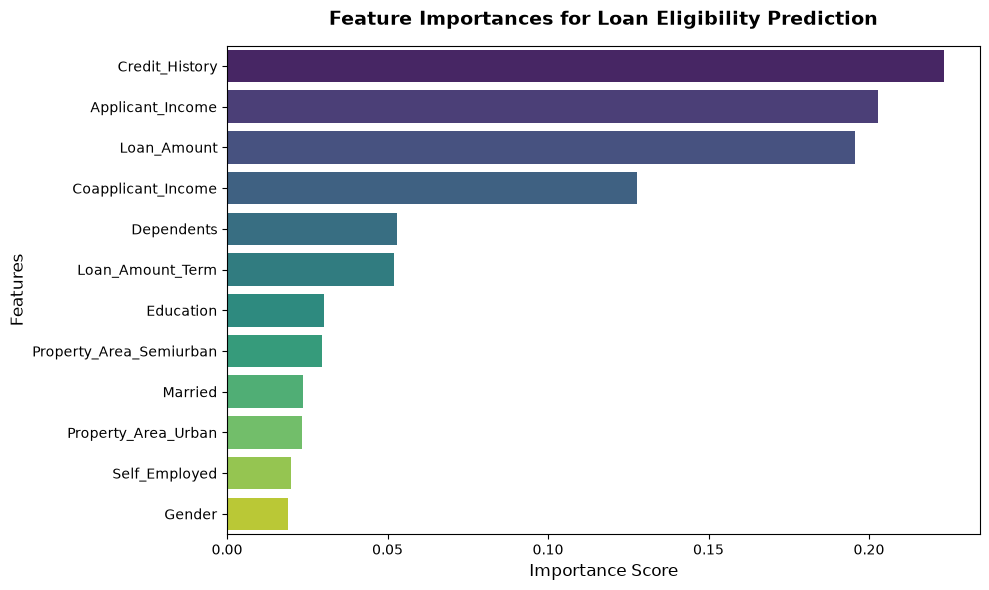

In [11]:
import matplotlib.pyplot as plt

# 1. Extract feature importances
importances = rf_model.feature_importances_

# 2. Create a Series with feature names
feature_importance_series = pd.Series(importances, index=X_train.columns).sort_values(ascending=False)

# 3. Create the plot
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importance_series.values, y=feature_importance_series.index, hue=feature_importance_series.index, palette='viridis', legend=False)

# 4. Customize the plot
plt.title('Feature Importances for Loan Eligibility Prediction', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()

# 5. Display the plot
plt.show()

In [13]:
import pickle as pkl
# 1. Save the trained Random Forest model to a file
model_filename = 'loan_eligibility_model.pkl'
with open(model_filename, 'wb') as f:
  pkl.dump(rf_model, f)